# Bank Customer Churn Analysis — Exploratory Data Analysis

**Project level:** Intermediate  
**Objective:** Explore customer churn patterns, compare customer groups, and identify variables associated with churn.

This notebook follows the structure of the original analysis. It focuses only on Python-based data inspection, cleaning, exploratory data analysis (EDA), visualisation, and basic statistical testing.

**Out of scope:** SQL, Power BI, and machine-learning model development.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

## 2. Load Dataset

In Kaggle, attach the **Bank Customer Churn** dataset using *Add Input*. The code searches the Kaggle input directory automatically. If you are running locally, update `local_file` to your CSV path.

In [2]:
import os
from pathlib import Path

file_name = "Customer-Churn-Records.csv"
kaggle_files = list(Path("/kaggle/input").rglob(file_name)) if Path("/kaggle/input").exists() else []

local_file = Path(file_name)

if kaggle_files:
    data_path = kaggle_files[0]
elif local_file.exists():
    data_path = local_file
else:
    raise FileNotFoundError(
        f"{file_name} was not found. Attach the Kaggle dataset or place the CSV beside this notebook."
    )

df = pd.read_csv(data_path)
print("Loaded file:", data_path)
print("Dataset shape:", df.shape)
df.head()

Loaded file: /kaggle/input/datasets/radheshyamkollipara/bank-customer-churn/Customer-Churn-Records.csv
Dataset shape: (10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


## 3. Understand the Dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

Rows: 10000
Columns: 18

Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain', 'Satisfaction Score', 'Card Type', 'Point Earned']


## 4. Data Cleaning and Quality Checks

The original dataset contains identifier columns that are not useful for the churn-pattern analysis. We remove these columns from the analysis copy, check duplicates and missing values, and retain the original target column `Exited`.

In [6]:
# Work on a copy so the raw dataframe remains available
df = df.copy()

# Remove identifier / name fields (not analytical predictors)
id_columns = ["RowNumber", "CustomerId", "Surname"]
existing_id_columns = [col for col in id_columns if col in df.columns]
df.drop(columns=existing_id_columns, inplace=True)

print("Removed identifier columns:", existing_id_columns)
print("Updated shape:", df.shape)

Removed identifier columns: ['RowNumber', 'CustomerId', 'Surname']
Updated shape: (10000, 15)


In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

missing_values = (
    df.isna()
      .sum()
      .to_frame("missing_count")
      .assign(missing_percent=lambda x: (x["missing_count"] / len(df) * 100).round(2))
      .sort_values("missing_count", ascending=False)
)
missing_values

Exact duplicate rows: 0


,missing_count,missing_percent
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0
HasCrCard,0,0.0
IsActiveMember,0,0.0
EstimatedSalary,0,0.0


In [8]:
# Remove exact duplicate rows only, if any are present
duplicate_count = df.duplicated().sum()
if duplicate_count > 0:
    df = df.drop_duplicates().copy()

print("Shape after duplicate check:", df.shape)
print("Missing values remaining:", int(df.isna().sum().sum()))

Shape after duplicate check: (10000, 15)
Missing values remaining: 0


## 5. Overall Churn Overview

In [9]:
target_counts = df["Exited"].value_counts().sort_index()
target_percent = df["Exited"].value_counts(normalize=True).sort_index() * 100

churn_summary = pd.DataFrame({
    "customer_count": target_counts,
    "percentage": target_percent.round(2)
})
churn_summary.index = ["Retained (0)", "Churned (1)"]
churn_summary

,customer_count,percentage
Retained (0),7962,79.62
Churned (1),2038,20.38


Total customers: 10,000
Churned customers: 2,038
Overall churn rate: 20.38%


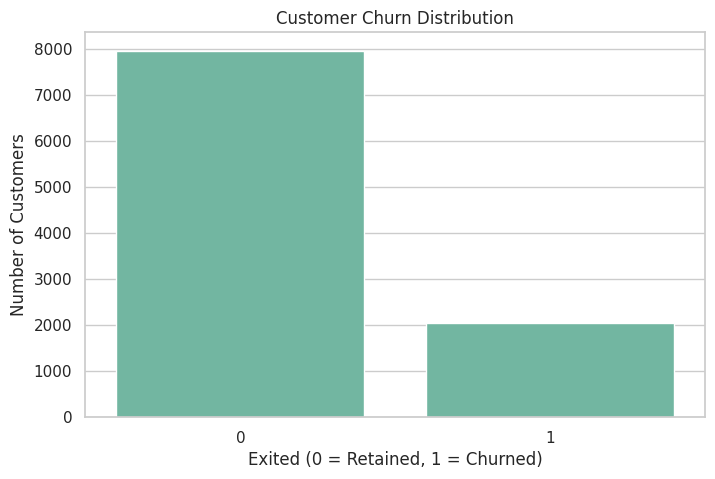

In [10]:
churn_rate = df["Exited"].mean() * 100
print(f"Total customers: {len(df):,}")
print(f"Churned customers: {int(df['Exited'].sum()):,}")
print(f"Overall churn rate: {churn_rate:.2f}%")

sns.countplot(data=df, x="Exited")
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()

## 6. Churn by Geography

Compare customer counts and churn rates across France, Germany, and Spain. Churn rate is calculated within each country, rather than comparing raw churn counts.

In [11]:
geo_summary = (
    df.groupby("Geography")["Exited"]
      .agg(total_customers="count", churned_customers="sum", churn_rate="mean")
)
geo_summary["churn_rate"] = (geo_summary["churn_rate"] * 100).round(2)
geo_summary.sort_values("churn_rate", ascending=False)

,total_customers,churned_customers,churn_rate
Geography,,,
Germany,2509,814,32.44
Spain,2477,413,16.67
France,5014,811,16.17


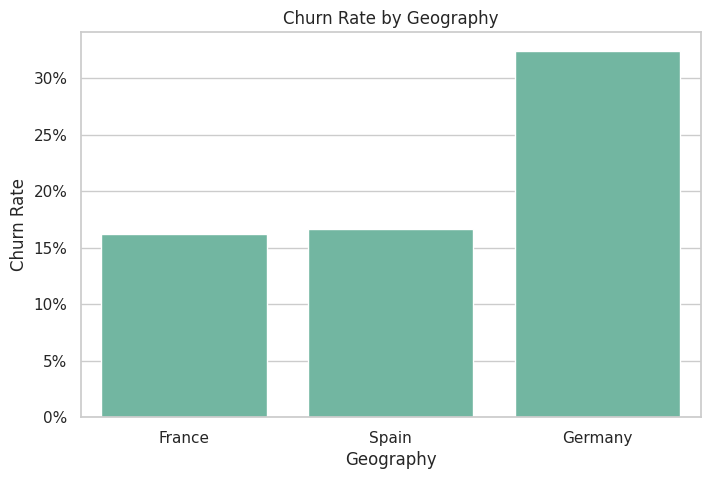

In [12]:
sns.barplot(data=df, x="Geography", y="Exited", errorbar=None)
plt.title("Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

In [13]:
geo_table = pd.crosstab(df["Geography"], df["Exited"])
chi2, p_value, dof, expected = chi2_contingency(geo_table)
print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.6g}")

Chi-square statistic: 300.63
P-value: 5.24574e-66


## 7. Churn by Age

Compare age distributions for retained and churned customers and calculate average age by churn status. A Mann–Whitney U test checks whether the two age distributions differ.

In [14]:
age_summary = df.groupby("Exited")["Age"].agg(["count", "mean", "median"]).round(2)
age_summary.index = ["Retained", "Churned"]
age_summary

,count,mean,median
Retained,7962,37.41,36.0
Churned,2038,44.84,45.0


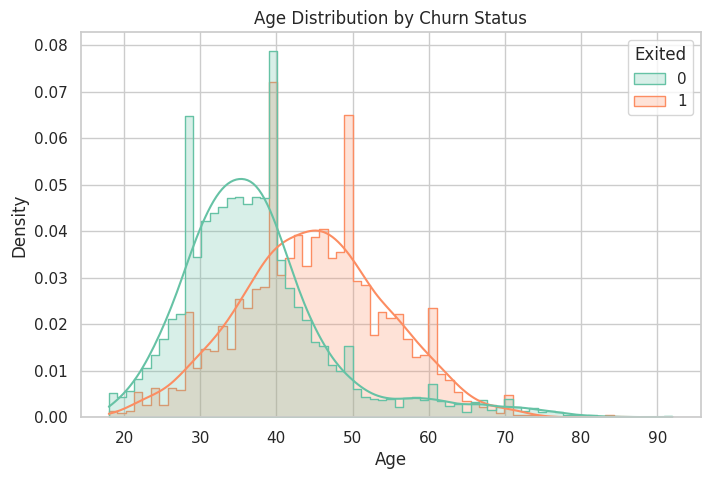

In [15]:
sns.histplot(data=df, x="Age", hue="Exited", kde=True, stat="density",
             common_norm=False, element="step")
plt.title("Age Distribution by Churn Status")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()

In [16]:
churned_age = df.loc[df["Exited"] == 1, "Age"].dropna()
retained_age = df.loc[df["Exited"] == 0, "Age"].dropna()

u_stat, p_value = mannwhitneyu(churned_age, retained_age, alternative="two-sided")
print(f"Mann-Whitney U statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.6g}")

Mann-Whitney U statistic: 11878815.00
P-value: 2.78026e-230


## 8. Churn by Account Balance

Compare average balance and churn rates for customers with zero and non-zero balances. The balance groups are descriptive segments, not causal explanations.

In [17]:
balance_summary = df.groupby("Exited")["Balance"].agg(["count", "mean", "median"]).round(2)
balance_summary.index = ["Retained", "Churned"]
balance_summary

,count,mean,median
Retained,7962,72742.75,92063.06
Churned,2038,91109.48,109344.23


In [18]:
df["BalanceGroup"] = np.where(df["Balance"].eq(0), "Zero Balance", "Has Balance")

balance_group_summary = (
    df.groupby("BalanceGroup")["Exited"]
      .agg(total_customers="count", churned_customers="sum", churn_rate="mean")
)
balance_group_summary["churn_rate"] = (balance_group_summary["churn_rate"] * 100).round(2)
balance_group_summary

,total_customers,churned_customers,churn_rate
BalanceGroup,,,
Has Balance,6383,1538,24.10
Zero Balance,3617,500,13.82


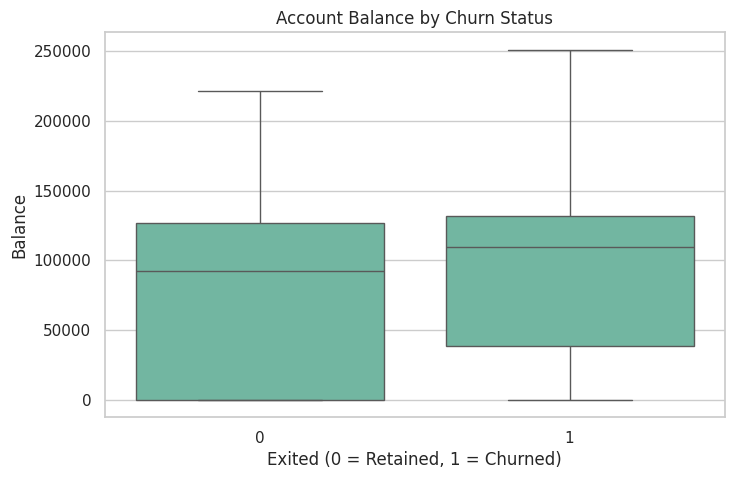

In [19]:
sns.boxplot(data=df, x="Exited", y="Balance")
plt.title("Account Balance by Churn Status")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Balance")
plt.show()

In [20]:
churned_balance = df.loc[df["Exited"] == 1, "Balance"].dropna()
retained_balance = df.loc[df["Exited"] == 0, "Balance"].dropna()

u_stat, p_value = mannwhitneyu(churned_balance, retained_balance, alternative="two-sided")
print(f"Mann-Whitney U statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.6g}")

Mann-Whitney U statistic: 9373909.50
P-value: 1.16877e-28


## 9. Churn by Number of Products

In [21]:
product_summary = (
    df.groupby("NumOfProducts")["Exited"]
      .agg(total_customers="count", churned_customers="sum", churn_rate="mean")
)
product_summary["churn_rate"] = (product_summary["churn_rate"] * 100).round(2)
product_summary

,total_customers,churned_customers,churn_rate
NumOfProducts,,,
1,5084,1409,27.71
2,4590,349,7.60
3,266,220,82.71
4,60,60,100.00


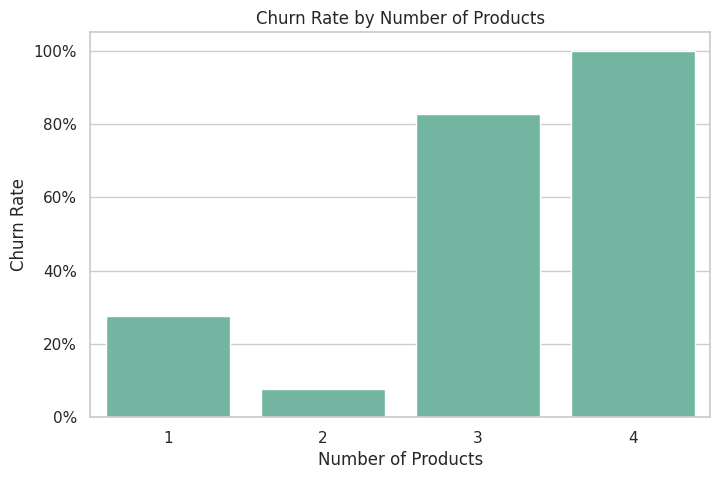

In [22]:
sns.barplot(data=df, x="NumOfProducts", y="Exited", errorbar=None)
plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

In [23]:
product_table = pd.crosstab(df["NumOfProducts"], df["Exited"])
chi2, p_value, dof, expected = chi2_contingency(product_table)
print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.6g}")

Chi-square statistic: 1501.50
P-value: 0


**Interpretation reminder:** Always check `total_customers` alongside churn rate. A very high rate in a small group can be unstable and should not be treated as a broad customer-level rule.

## 10. Churn by Active Membership

In [24]:
active_summary = (
    df.groupby("IsActiveMember")["Exited"]
      .agg(total_customers="count", churned_customers="sum", churn_rate="mean")
)
active_summary["churn_rate"] = (active_summary["churn_rate"] * 100).round(2)
active_summary.index = ["Inactive", "Active"]
active_summary

,total_customers,churned_customers,churn_rate
Inactive,4849,1303,26.87
Active,5151,735,14.27


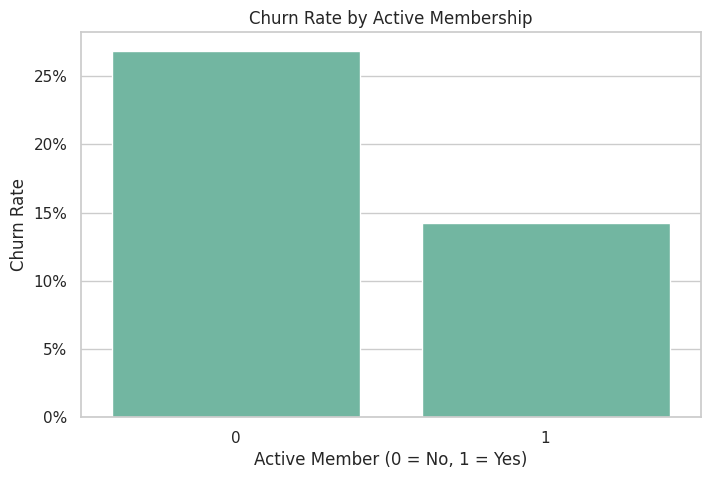

In [25]:
sns.barplot(data=df, x="IsActiveMember", y="Exited", errorbar=None)
plt.title("Churn Rate by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

In [26]:
active_table = pd.crosstab(df["IsActiveMember"], df["Exited"])
chi2, p_value, dof, expected = chi2_contingency(active_table)
print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.6g}")

Chi-square statistic: 243.69
P-value: 6.15317e-55


## 11. Complaint Status — Data Quality and Leakage Check

The original analysis found that `Complain` is almost a duplicate of `Exited`. We examine this relationship as an EDA/data-quality warning. It should not be interpreted as a genuine early warning factor because complaint timing may occur at or after the churn event.

In [27]:
complaint_table = pd.crosstab(df["Complain"], df["Exited"], margins=True)
complaint_table

Exited,0,1,All
Complain,,,
0,7952,4,7956
1,10,2034,2044
All,7962,2038,10000


In [28]:
complaint_churn_rate = (df.groupby("Complain")["Exited"].mean() * 100).round(2)
complaint_corr = df["Complain"].corr(df["Exited"])
print("Churn rate by complaint status (%):")
display(complaint_churn_rate)
print(f"Correlation between Complain and Exited: {complaint_corr:.4f}")

Churn rate by complaint status (%):


Complain
0     0.05
1    99.51
Name: Exited, dtype: float64

Correlation between Complain and Exited: 0.9957


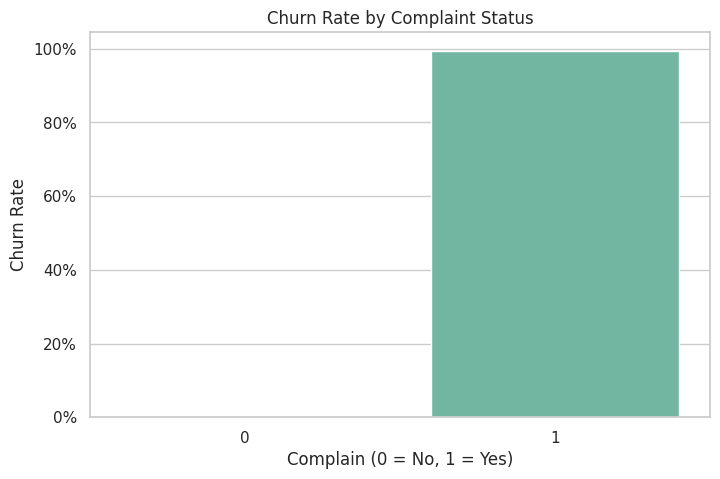

In [29]:
sns.barplot(data=df, x="Complain", y="Exited", errorbar=None)
plt.title("Churn Rate by Complaint Status")
plt.xlabel("Complain (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

## 12. Churn by Satisfaction Score

In [30]:
satisfaction_summary = (
    df.groupby("Satisfaction Score")["Exited"]
      .agg(total_customers="count", churned_customers="sum", churn_rate="mean")
)
satisfaction_summary["churn_rate"] = (satisfaction_summary["churn_rate"] * 100).round(2)
satisfaction_summary

,total_customers,churned_customers,churn_rate
Satisfaction Score,,,
1,1932,387,20.03
2,2014,439,21.80
3,2042,401,19.64
4,2008,414,20.62
5,2004,397,19.81


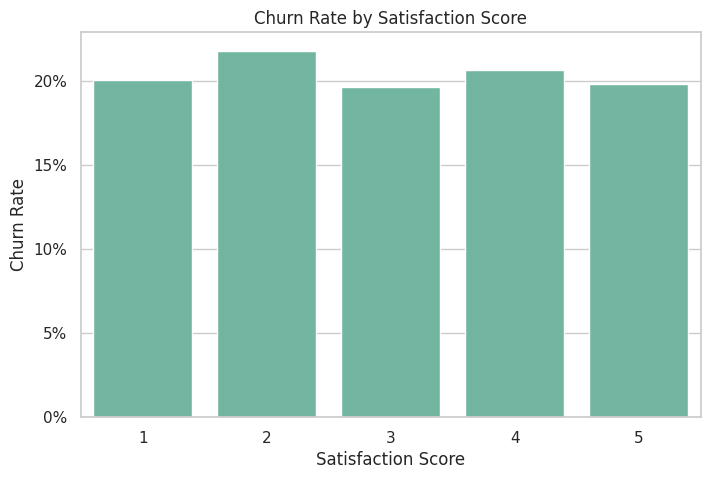

In [31]:
sns.barplot(data=df, x="Satisfaction Score", y="Exited", errorbar=None)
plt.title("Churn Rate by Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

In [32]:
satisfaction_table = pd.crosstab(df["Satisfaction Score"], df["Exited"])
chi2, p_value, dof, expected = chi2_contingency(satisfaction_table)
print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.6g}")

Chi-square statistic: 3.80
P-value: 0.433365


## 13. Correlation Analysis

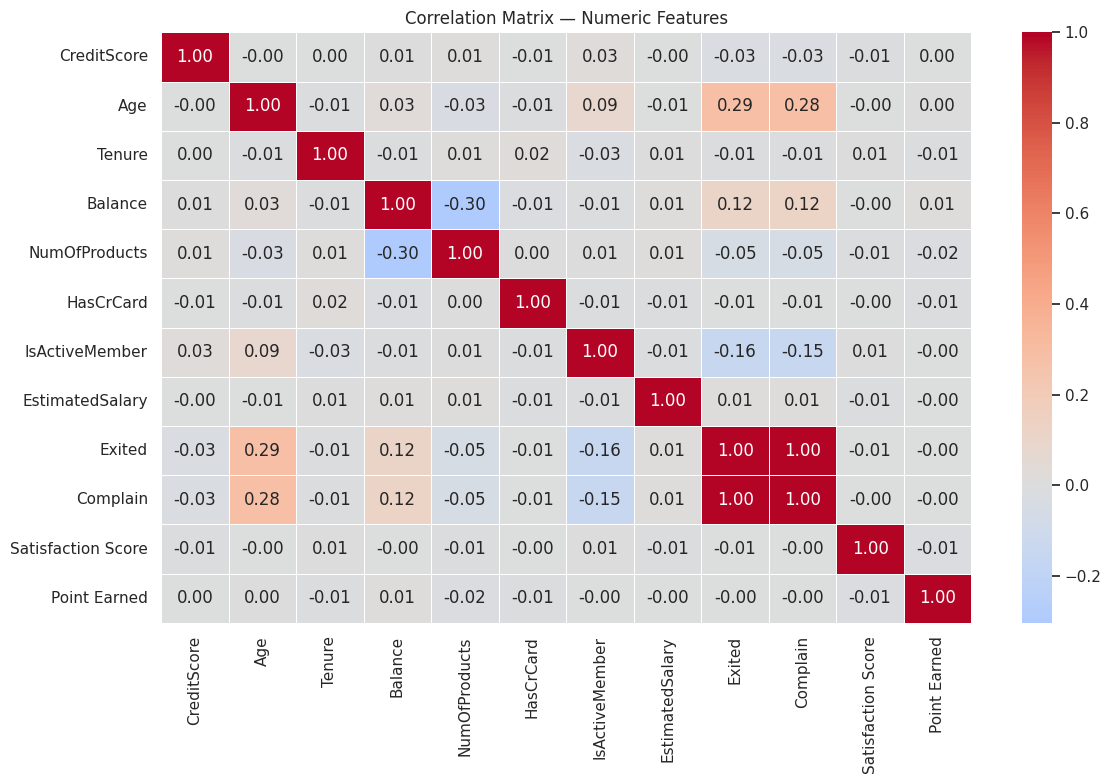

In [33]:
numeric_df = df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            linewidths=0.4)
plt.title("Correlation Matrix — Numeric Features")
plt.tight_layout()
plt.show()

## 14. EDA Summary

Use the outputs generated above to write the final findings. Avoid treating correlation or statistical significance as proof of causation.

Suggested points to report:
- Overall churn rate and customer count.
- Geography with the highest churn rate, including its customer count.
- Age and balance differences between retained and churned customers.
- Product groups with high churn, alongside their sample sizes.
- Difference between active and inactive members.
- Whether satisfaction score shows a clear pattern.
- The `Complain` field's potential target leakage limitation.

In [34]:
# Compact summary table for the main categorical segments
summary_tables = []

for column in ["Geography", "NumOfProducts", "IsActiveMember", "Satisfaction Score"]:
    temp = (
        df.groupby(column)["Exited"]
          .agg(total_customers="count", churned_customers="sum", churn_rate="mean")
          .reset_index()
    )
    temp["churn_rate"] = (temp["churn_rate"] * 100).round(2)
    temp.insert(0, "segment", column)
    temp = temp.rename(columns={column: "segment_value"})
    summary_tables.append(temp)

eda_segment_summary = pd.concat(summary_tables, ignore_index=True)
eda_segment_summary

,segment,segment_value,total_customers,churned_customers,churn_rate
0,Geography,France,5014,811,16.17
1,Geography,Germany,2509,814,32.44
2,Geography,Spain,2477,413,16.67
3,NumOfProducts,1,5084,1409,27.71
4,NumOfProducts,2,4590,349,7.60
5,NumOfProducts,3,266,220,82.71
6,NumOfProducts,4,60,60,100.00
7,IsActiveMember,0,4849,1303,26.87
8,IsActiveMember,1,5151,735,14.27
9,Satisfaction Score,1,1932,387,20.03


## 15. Save the Cleaned Analysis Dataset (Optional)

This saves the cleaned dataframe used in the EDA. The additional `BalanceGroup` column is an analysis segment created in this notebook.

In [35]:
output_file = "bank_customer_churn_eda_cleaned.csv"
df.to_csv(output_file, index=False)
print(f"Saved: {output_file}")

Saved: bank_customer_churn_eda_cleaned.csv
